Joonseo Bang & KhevinJae

Background information : This dataset represnets a heart disease database with 270 instances and 13 features such as age, sex, chest-pain, rest-bp, serum-chol, fasting-blood-sugar, electrocardiographic, max-heart-rate, angina, oldpeak, slope, major-vessels, and thal. The purpose of this assignment is to apply the K-Nearest Neighbors (KNN) algorithm to predict whether a patient has heart disease based on 13 clinical features. and in this assignment we convert that fact as 0 and 1 for whether there is a heart disease or not.

Main point : Whether KNN could accurately classify the presence or absence of heart dieases based on patient's clinical features?

Source link : https://archive.ics.uci.edu/dataset/145/statlog+heart

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
train_test_split, # Split data into train/test sets
cross_val_score # Cross-validation for robust evaluation
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
accuracy_score,
classification_report,
confusion_matrix
)

Brings the train_test_split, accuracy_score, classification_report, confusion_matrix before activating the K-nearst_neighbors.

It splits data into train/test sets


And The cross-validation is for robust evaluation.

In [4]:
column_names = [
    'Age', 'Sex', 'Chest_Pain', 'Rest_BP',
    'Serum_Chol', 'Fasting_Blood_Sugar',
    'ECG', 'Max_Heart_Rate', 'Angina',
    'Oldpeak', 'Slope', 'Major_Vessels',
    'Thal', 'Heart_Disease'
]

df = pd.read_csv(
    'heart.dat',
    sep=r'\s+',
    header=None,
    names=column_names
)

# Convert target labels into 0 and 1
df['Heart_Disease'] = df['Heart_Disease'].map({
    1: 0,
    2: 1
})

print("Dataset Overview")
print("Total samples:", df.shape[0])
print("Number of features:", df.shape[1] - 1)
print("Number of classes:", df['Heart_Disease'].nunique())

print("\nClass distribution:")
print(df['Heart_Disease'].value_counts())

print("\nFirst 5 rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset Overview
Total samples: 270
Number of features: 13
Number of classes: 2

Class distribution:
Heart_Disease
0    150
1    120
Name: count, dtype: int64

First 5 rows:
    Age  Sex  Chest_Pain  Rest_BP  Serum_Chol  Fasting_Blood_Sugar  ECG  \
0  70.0  1.0         4.0    130.0       322.0                  0.0  2.0   
1  67.0  0.0         3.0    115.0       564.0                  0.0  2.0   
2  57.0  1.0         2.0    124.0       261.0                  0.0  0.0   
3  64.0  1.0         4.0    128.0       263.0                  0.0  0.0   
4  74.0  0.0         2.0    120.0       269.0                  0.0  2.0   

   Max_Heart_Rate  Angina  Oldpeak  Slope  Major_Vessels  Thal  Heart_Disease  
0           109.0     0.0      2.4    2.0            3.0   3.0              1  
1           160.0     0.0      1.6    2.0            0.0   7.0              0  
2           141.0     0.0      0.3    1.0            0.0   7.0              1  
3           105.0     1.0      0.2    2.0            1.

According to above, the dataset consists of 270 data samples, each with 13 features. The target variable, 'Heart_Disease', has been converted into a binary value, where 0 indicates the absence of heart disease and 1 indicates its presence. Furthermore, before training the KNN model, the class distribution is examined and the data is checked for any missing values.

In [5]:
print("Average measurements by heart disease status:")

print(df.groupby('Heart_Disease').mean().round(3))

Average measurements by heart disease status:
                  Age    Sex  Chest_Pain  Rest_BP  Serum_Chol  \
Heart_Disease                                                   
0              52.707  0.553       2.820  128.867     244.213   
1              56.592  0.833       3.617  134.442     256.467   

               Fasting_Blood_Sugar    ECG  Max_Heart_Rate  Angina  Oldpeak  \
Heart_Disease                                                                
0                            0.153  0.860         158.333   0.153    0.623   
1                            0.142  1.225         138.858   0.550    1.584   

               Slope  Major_Vessels   Thal  
Heart_Disease                               
0              1.400          0.287  3.787  
1              1.817          1.150  5.833  


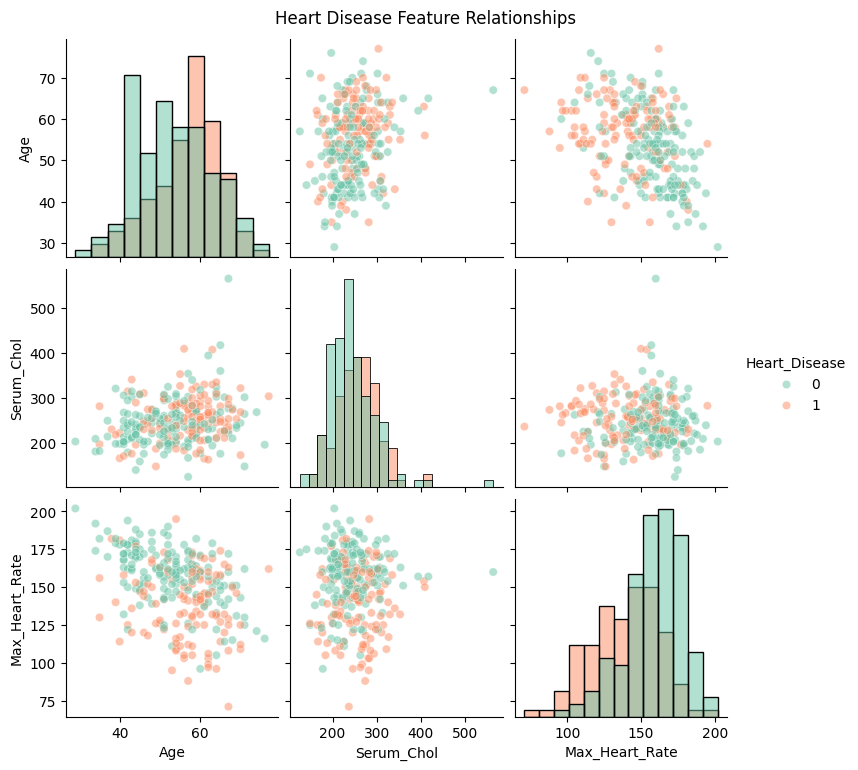

In [6]:
plot_features = [
    'Age',
    'Serum_Chol',
    'Max_Heart_Rate',
    'Heart_Disease'
]

sns.pairplot(
    df[plot_features],
    hue='Heart_Disease',
    palette='Set2',
    diag_kind='hist',
    plot_kws={'alpha': 0.5}
)

plt.suptitle(
    'Heart Disease Feature Relationships',
    y=1.02
)

plt.show()

In this case, it is important to determine how well-separated the data from the two groups are.

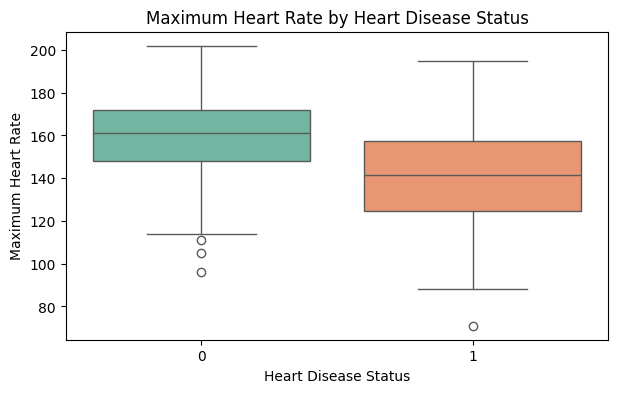

In [7]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x='Heart_Disease',
    y='Max_Heart_Rate',
    hue='Heart_Disease',
    palette='Set2',
    legend=False
)

plt.xlabel('Heart Disease Status')
plt.ylabel('Maximum Heart Rate')
plt.title('Maximum Heart Rate by Heart Disease Status')

plt.show()

These are for exploring the relationships between patient characteristics and heart disease status. Features that show a clearer separation between the two classes may be useful for KNN classification.

In [8]:
X = df.drop('Heart_Disease', axis=1)
y = df['Heart_Disease']

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 216
Testing samples: 54

Training class distribution:
Heart_Disease
0    120
1     96
Name: count, dtype: int64

Testing class distribution:
Heart_Disease
0    30
1    24
Name: count, dtype: int64


Train/Test split by following the examples from canvas.

In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Since KNN is a distance-based classification algorithm, feature scaling is essential. We apply StandardScaler to ensure that features with large numerical ranges do not dominate the distance calculations. To prevent data leakage, the scaler is fitted only on the training data.

In [11]:
knn = KNeighborsClassifier(n_neighbors=7)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print(f"Overall Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Overall Accuracy: 79.63%

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.73      0.80        30
           1       0.72      0.88      0.79        24

    accuracy                           0.80        54
   macro avg       0.80      0.80      0.80        54
weighted avg       0.81      0.80      0.80        54



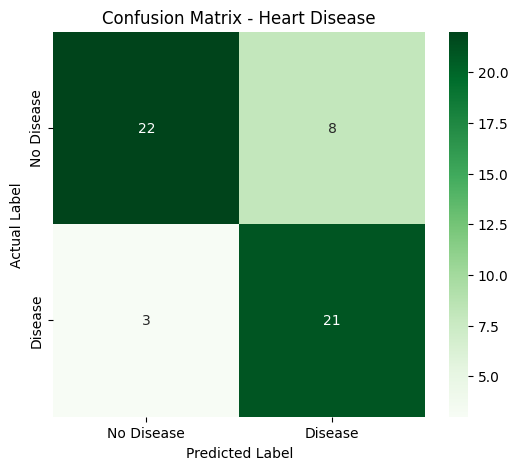

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Heart Disease')

plt.show()

In this classification process, false negatives are a particularly concerning issue, as they mean a patient with a heart condition could be incorrectly classified as healthy. Therefore, when evaluating a model, it is essential to consider not only overall accuracy but also the recall for the positive class.

In [13]:
from sklearn.pipeline import make_pipeline

k_range = range(1, 31)

cv_means = []
cv_stds = []

for k in k_range:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

    print(f"K={k}: CV Accuracy = {scores.mean():.2%}")

K=1: CV Accuracy = 78.71%
K=2: CV Accuracy = 79.64%
K=3: CV Accuracy = 81.48%
K=4: CV Accuracy = 81.95%
K=5: CV Accuracy = 83.35%
K=6: CV Accuracy = 83.79%
K=7: CV Accuracy = 85.62%
K=8: CV Accuracy = 84.71%
K=9: CV Accuracy = 82.42%
K=10: CV Accuracy = 82.88%
K=11: CV Accuracy = 82.42%
K=12: CV Accuracy = 83.33%
K=13: CV Accuracy = 83.33%
K=14: CV Accuracy = 81.95%
K=15: CV Accuracy = 82.41%
K=16: CV Accuracy = 82.86%
K=17: CV Accuracy = 83.32%
K=18: CV Accuracy = 82.86%
K=19: CV Accuracy = 84.71%
K=20: CV Accuracy = 84.70%
K=21: CV Accuracy = 84.70%
K=22: CV Accuracy = 83.78%
K=23: CV Accuracy = 83.78%
K=24: CV Accuracy = 84.70%
K=25: CV Accuracy = 83.78%
K=26: CV Accuracy = 84.24%
K=27: CV Accuracy = 84.25%
K=28: CV Accuracy = 83.78%
K=29: CV Accuracy = 83.78%
K=30: CV Accuracy = 84.24%


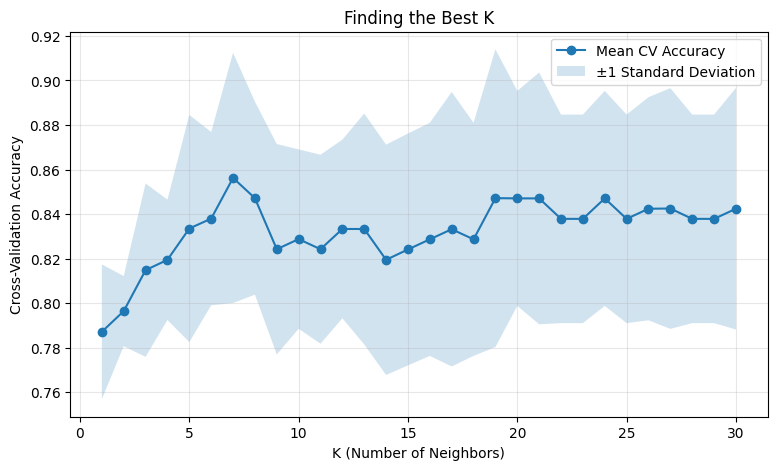

Best K: 7
Best CV Accuracy: 85.62%


In [14]:
cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)

plt.figure(figsize=(9, 5))

plt.plot(
    k_range,
    cv_means,
    marker='o',
    label='Mean CV Accuracy'
)

plt.fill_between(
    k_range,
    cv_means - cv_stds,
    cv_means + cv_stds,
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Cross-Validation Accuracy')
plt.title('Finding the Best K')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

best_k = list(k_range)[np.argmax(cv_means)]

print("Best K:", best_k)
print(f"Best CV Accuracy: {cv_means.max():.2%}")

To determine the optimal number of neighbors, 5-fold cross-validation is performed while varying the K value from 1 to 30. If the K value is too small, it may lead to overfitting, whereas if it is too large, it may result in underfitting. The K value that yields the highest average cross-validation accuracy is selected for the final model.

In [15]:
final_model = KNeighborsClassifier(
    n_neighbors=best_k
)

final_model.fit(X_train_scaled, y_train)

y_pred_final = final_model.predict(X_test_scaled)

final_accuracy = accuracy_score(
    y_test,
    y_pred_final
)

print(f"Best K: {best_k}")
print(f"Final Test Accuracy: {final_accuracy:.2%}")

print("\nFinal Classification Report:")
print(classification_report(y_test, y_pred_final))

Best K: 7
Final Test Accuracy: 79.63%

Final Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.73      0.80        30
           1       0.72      0.88      0.79        24

    accuracy                           0.80        54
   macro avg       0.80      0.80      0.80        54
weighted avg       0.81      0.80      0.80        54



In [16]:
comparison = pd.DataFrame({
    'Model': ['Initial KNN', 'Optimized KNN'],
    'K': [7, best_k],
    'Accuracy': [accuracy, final_accuracy]
})

print(comparison)

           Model  K  Accuracy
0    Initial KNN  7  0.796296
1  Optimized KNN  7  0.796296


This can demonstrate how optimizing the K-value through cross-validation affected the actual test accuracy.

In [17]:
new_patients = pd.DataFrame({
    'Age': [35, 65],
    'Sex': [0, 1],
    'Chest_Pain': [3, 4],
    'Rest_BP': [115, 155],
    'Serum_Chol': [180, 290],
    'Fasting_Blood_Sugar': [0, 1],
    'ECG': [0, 2],
    'Max_Heart_Rate': [175, 110],
    'Angina': [0, 1],
    'Oldpeak': [0.0, 2.5],
    'Slope': [1, 2],
    'Major_Vessels': [0, 2],
    'Thal': [3, 7]
})

new_patients_scaled = scaler.transform(
    new_patients
)

predictions = final_model.predict(
    new_patients_scaled
)

probabilities = final_model.predict_proba(
    new_patients_scaled
)

for i in range(len(new_patients)):

    print(f"\nPatient #{i+1}")

    print("Predicted class:", predictions[i])

    for cls, prob in zip(
        final_model.classes_,
        probabilities[i]
    ):
        print(f"Class {cls}: {prob:.2%}")


Patient #1
Predicted class: 0
Class 0: 100.00%
Class 1: 0.00%

Patient #2
Predicted class: 1
Class 0: 0.00%
Class 1: 100.00%


In conclusion, the initial K value was 7 which achieved the initial accuracy of 79.63% and through the cross-validation, the best K was also 7 and the CV accuracy was 85.62%.


As the optimal K value was identical to the initial K value, the final test accuracy remained at 79.63% from the initical accuracy. Although optimization did not increase the test accuracy, it gave the suitability of initial K value from tested K values.


Eventually, the K_nearest_neighbors shows its ability to classify the presence or absence of heart disease based on the given features.